In [2]:
# Data Source
import yfinance as yf

# Numerical Calculations
import numpy as np
import pandas as pd
import statsmodels.tsa.stattools as ts
import statsmodels.api as sm
from collections import deque

# Visualizations 
import matplotlib.pyplot as plt
import seaborn as sns

# Backtesting
import pyfolio as pf

import datetime as dt
import warnings
warnings.filterwarnings('ignore')

### Outline

**Module 1: Stocks Selection**
- Determine a set of stocks *(Financial Research)*

**Module 2: Pair Validation**
- Conduct a long-term *co-integration test* and *Correlation test* for various pairs of stocks over the past 3 years

**Module 3: Kalman Filter and Signal Generation**
- Intialize the kalman filter 
- Update the kalman filter with current price

**Module 4: Strategy Optimization**
- Define intial conditions for strategy execution like entry and exit thresholds and stop losses
- Optimize on the last 6 months of data and re-optimize every month 

**Module 5: Backtesting**
- Comparison to buy and hold, look at bullish periods and bearish periods 
- Tracking cumulative returns, VaR, Max Drawdown 

*Note for Bakctesting:* Be careful of look ahead bias as the correlations or betas calculated cannot be used to trade during times which used prices from before those trading dates.

## Module 1: Stock Selection

Stock Pairs to use for outline of pairs trading strategy:
- Coca Cola & Pepsi 
- Lowe's & Home Depot
- Visa & Mastercard

## Module 2: Pair Validation

### Sample Data

In [3]:
def LogReturnsPrices(pair:list, start_date, end_date):
    # Get Log Prices
    data = yf.download(pair, start_date, end_date, auto_adjust=True)['Close']
    data = data.dropna()
    log_data = np.log(data)
    stock1prices = log_data.iloc[:, 0]
    stock2prices = log_data.iloc[:, 1]
    
    # Convert to Dataframe
    df_stock1 = stock1prices.to_frame()
    df_stock2 = stock2prices.to_frame()
    
    # Get Log Returns and adds them to individual stock dataframes
    log_returns1 = (df_stock1 - df_stock1.shift(1)).add_suffix('_LogRet')
    log_returns2 = (df_stock2 - df_stock2.shift(1)).add_suffix('_LogRet')

    # Rename Columns
    df_stock1 = df_stock1.join(log_returns1)
    df_stock1.columns = ['LogPrices', 'LogReturns']
    df_stock1 = df_stock1.add_prefix(f'{pair[0]}_')
    
    df_stock2 = df_stock2.join(log_returns2)
    df_stock2.columns = ['LogPrices', 'LogReturns']
    df_stock2 = df_stock2.add_prefix(f'{pair[1]}_')

    # Combine Dataframes
    combined_df = df_stock1.join(df_stock2)
    combined_df = data.join(combined_df)
    return combined_df

In [4]:
# Stock Pairs
pair1 = ['KO', 'PEP']
pair2 = ['HD', 'LOW']
pair3 = ['V', 'MA']
pair4 = ['GOOGL', 'GOOG']
pair5 = ['XOM', 'CVX']
pair6 = ['COST', 'BJ']
pair7 = ['WMT', 'COST']
pair8 = ['NKE', 'ADDYY']
pair9 = ['BKNG', 'EXPE']
pair10 = ['MCD', 'YUM']
pair11 = ['T', 'VZ']
pair12 = ['AMD', 'INTC']
pair13 = ['LMT', 'RTX']
pair14 = ['DAL', 'UAL']

# generate a list of list of these pairs
PAIRS = [pair1, pair2, pair3, pair4, pair5, pair6, pair7, pair8, pair9, pair10, pair11, pair12, pair13, pair14]

In [13]:
# Date Period for Cointegration Test
START_DATE = '2017-01-02'
END_DATE='2020-03-28'

### Cointegration Test

Purpose is to find pairs which are co-integrated in the long term. This test does not need to be conducted on a daily, weekly or even monthly scale. This will be used whenever we have a new selection of stocks to conduct our analysis on.

In [11]:
def CointegrationTest(pair, start_date, end_date, threshold):
    log_data = LogReturnsPrices(pair, start_date=start_date, end_date=end_date).iloc[:,[2,4]]
    _, pvalue, _ = ts.coint(log_data.iloc[:,0], log_data.iloc[:,1])
    return pvalue

In [8]:
THRESHOLD = 0.10
VALID_PAIRS = []

In [14]:
for pair in PAIRS:
    pvalue = CointegrationTest(pair, start_date=START_DATE, end_date=END_DATE, threshold=THRESHOLD)
    if pvalue < THRESHOLD:
        VALID_PAIRS.append(pair)
        print(f"Pair {pair[0]} and {pair[1]} is cointegrated with p-value: {pvalue:.4f}")
    else:
        print(f"Pair {pair[0]} and {pair[1]} is not cointegrated with p-value: {pvalue:.4f}")

VALID_PAIRS

[*********************100%***********************]  2 of 2 completed


Pair KO and PEP is not cointegrated with p-value: 0.3466


[*********************100%***********************]  2 of 2 completed


Pair HD and LOW is not cointegrated with p-value: 0.2384


[*********************100%***********************]  2 of 2 completed


...

[*********************100%***********************]  2 of 2 completed


Pair LMT and RTX is not cointegrated with p-value: 0.8688


[*********************100%***********************]  2 of 2 completed

Pair DAL and UAL is not cointegrated with p-value: 0.4066


[['V', 'MA'], ['XOM', 'CVX'], ['V', 'MA'], ['COST', 'BJ']]

In [ ]:
# Stock Pairs
pair1 = ['KO', 'PEP']
pair2 = ['HD', 'LOW']
pair3 = ['V', 'MA']
pair4 = ['GOOGL', 'GOOG']
pair5 = ['XOM', 'CVX']



PAIRS = [pair6, pair7, pair8, pair9, pair10, pair11, pair12, pair13, pair14]

We need to choose a threshold pvalue for all stocks in the pair trading portfolio to almost guarente long-term spread convergence. Mostly commonly used is p-value of $.10$. Anything above this threshold we would drop (In this case, Lowes and Home Depot) as pair a potential trading for the portfolio.

If we use the period of the last 8 years to test for co-integration this is long enough to be considered a long term relationship but not too long to admit the variance in prices over on the daily scale.  

### Correlation Values

These correlation values will be calculated before every trade to ensure that the stocks should at least move in the same direction in the short term. The correlations will be **rolling** and be calualted with a 60 day window size meaning that on the day of trading the stock, the correlation of between the pair will be calculated back 60 days.

The minimum threshold for correlation will be somewhere around $0.8$. The goal with this metric is to ensure there is "momentum" or a short-term correlation between stocks too.

In [15]:
# Correlation Function for the Last 6 Months
def RollingCorr(pair: list):
    end_date = dt.date.today()
    start_date = end_date - pd.DateOffset(months=6)
    df = yf.download(pair, start_date, end_date, auto_adjust=True)['Close']
    returns = df.pct_change().dropna()
    correlation = returns[pair[0]].corr(returns[pair[1]])
    return correlation

In [16]:
corr_thres = 0.85

for pair in VALID_PAIRS:
    corr = RollingCorr(pair)
    print(f"The rolling correlation between {pair[0]} and {pair[1]} is: {corr:.4f}")
    if corr < corr_thres:
        VALID_PAIRS.remove(pair)
        print(f"Pair {pair[0]} and {pair[1]} is highly correlated")

VALID_PAIRS

[*********************100%***********************]  2 of 2 completed


The rolling correlation between V and MA is: 0.8873


[*********************100%***********************]  2 of 2 completed


The rolling correlation between XOM and CVX is: 0.8035
Pair XOM and CVX is highly correlated


[*********************100%***********************]  2 of 2 completed

The rolling correlation between COST and BJ is: 0.4520
Pair COST and BJ is highly correlated


[['V', 'MA'], ['V', 'MA']]

## Module 3: Kalman Filter and Signal Generation

Instead of using a static or even a rolling beta calculation which will lag behind when it comes to spread opprotunities or even when regeme changes occur. A kalman filter is a much better solution and is a great method to learn in general for quant finance as we want instanteuous updates for new data / changes for any trading algorithm.

For the kalman filter we will: 
1. Calculate the beta of the returns
2. Use beta to construct an sythentic portfolio (spread) between the two log stock prices
3. normalize the spread to generate a signal (-1,1)
4. generate signals for values of the spread 

A recursive algorithm used to estimate the state of a dynamic system from a series of noisy measurements using a *state-space model approach*. 
1. We give an original value we is our best guess
2. Create a prediction using randomness for the next state and error covariance
3. Update the prediction given the actual observed result

In terms of pairs trading its used to find the **hedge ratio** or **beta** between pairs of stocks representing the the scalling factor of one stock to equal the other.

#### State Equation
This describes how the hedge ratio ($\beta$) evolves from one step to the next assuming that $\beta$ follows a random walk:
$$
\beta_{t} = \beta_{t-1} + w_{t}
$$
- $\beta_{t}$ :  Hedge ratio at time t
- $w_{t}$ : Process noise where $w_{t} \sim N(0,Q)$ 

#### Measurement Equation 
Dynamic regression equation linking the observed market prices to the hedge ratio which changes over time. 
$$ 
Y_{t} = \beta_{t}X_{t} + \alpha_{t} + v_{t}
$$
- $Y_{t}, X_{t}$: Prices of the two stocks
- $\alpha_{t}$: Intercept which can also be tracked as the state and represents the consistent fair value spread if the equation is rearraged.
- $v_{t}$: Measurement noise (*market microstructure noise or temporary noise*) where $v_{t} \sim N(0,R)$
The state vector which we are constantly tracking is $\theta_{t} = \begin{bmatrix} \alpha_{t} \\ \beta_{t} \end{bmatrix}$

### Recursive Process
1. Predict the *state* using the historic $\beta_{t-1}$ and predict *error covariance* using historic $P_{t-1}$
2. *Update* process:
    - Calculate *innovation* which represents the difference between the actual price ($Y_{t}$) and the predicted price ($\hat{\beta}_{t | t-1}X_{t} + \alpha_{t}$)
    - Calculate *kalman gain* which represents the importance of this *innovation*, meaning how much should the model correct itself?
    - Update the predicted *hedge ratio* and *error covariance matrix* for the next interation.
#### Prediction
Using the current state and uncertainty:
- **Predicting Next State**: $\hat{\beta}_{t | t-1} = \hat{\beta}_{t - 1| t-1}$ , (Our best guess of the today's hedge ratio is yesterdays hedge ratio, martingale property)
- **Error Covariance Prediction**: $P_{t|t-1} = P_{t-1|t-1} + Q$ , (Uncertainty grows everyday), the initial value for $P_{0} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$ , (this should be tweaked initially) $Q = \begin{bmatrix} \sigma_{\alpha}^{2} & 0 \\ 0 & \sigma_{\beta}^{2} \end{bmatrix}$
#### Update
Once the actual observed price occurs this is where the magic happens. The first thing the model does is calculate the *innovation* ($e_{t}$) which is the difference between the actual price and the observed price and it is calculated as follows:
$$
e_{t} = Y_{t} - (\hat{\beta}_{t | t-1}X_{t} + \alpha_{t})
$$
Now we need to determine the weight of this new information called the *Kalman Gain* ($K_{t}$). How impactful is this new information on the model? Depending on the outcome whether to listen to the *mathematical model* or *new measurement*.  It is determined by the ratio of the uncertainty in the model ($P$) vs. the uncertainty in the measurement ($R$). 
$$ K_{t} = \frac{ P_{t|t-1}H^{T} }{ HP_{t|t-1}H^{T} + R }$$
$H$ is the price of the independent stock and in terms of the intercept regression model and is called the *Observation Matrix*. It maps your hidden states ($\alpha$ and $\beta$) to the actual price of stock $Y$. Without this matrix, the filter wouldn't know how a change in the hedge ratio relates to a change in the observed price.
$$H_{t} = \begin{bmatrix} 1 & X_{t}\end{bmatrix}$$
Then now update the hedge ratio to $\hat{\beta}_{t|t}$ given the *Innovation* and *Kalman Gain* which is essentially saying how correct was our previous guess.
$$ 
\hat{\beta}_{t|t} = \hat{\beta}_{t|t-1} + K_{t}e_{t}
$$
and also update $P_{t|t-1}$ to $P_{t|t}$
$$
P_{t|t} = (I - K_{t}H_{t})P_{t|t-1}
$$
### Application to Trading


### Constant Parameters $R$ and $Q$

These are the tuning parameters of the algorithm and are set as constants before your start the filter and dictate if the trading model will be *aggressive* or *smooth*.

#### Process Noise Covariance ($Q$)
This represents how much much you expect the hedge ratio or beta to drift over time (how do we optimize this parameter). This parameter is crucial during the *prediction step* for the error covariance ($P_{t|t-1}$) 
$$ P_{t|t-1} = P_{t-1|t-1} + Q $$
Different levels of $Q$ tells us different things about our system:
- **High $Q$**: The relationship between the stocks is *very unstable* and the filter will react quickly to price changes and "chase" random noise
- **Low $Q$**: The relationship between stocks is *very stable*, the hedge ratio will change slowly creating a smoother and less reactive model.

#### Measurement Noise Covariance ($R$)
This represents the amount of *distrust* we have in the current price data which may be leading us away from their true value in relation with one another. We know the observed prices are not perfect and are not completely representative of the true value of a company stock and are influenced by:
- Bid-Ask Spreads
- Microstructure Noise
- Rounding and Latency
The actual parameter appears in the equation for *Kalman Gain*.
$$
K_{t} = \frac{ P_{t|t-1}H^{T} }{ HP_{t|t-1}H^{T} + R }
$$
Different levels in $R$ tells us various things about our system:
- **High** $R$: Market prices are very noisy so don't change the hedge ratio just because of one abnormal price change. *Smooth and stable hedge ratio*.
- **Low** $R$: Market prices are extremely accurate, if prices move greatly from the "equilibrium" with one another then the hedge ratio likely changed. *Fast and twitchy hedge ratio*.

Note: *Since we are using log prices, the R value must be very small to match the scale of the price changes.* 

#### Calculating the Spread

For this pairs trading strategy, the trading signals are based on the spread of the stocks denote by,
$$ 
Z_{t} = Y_{t} - \beta_{t}X_{t}
$$

then we normalize,
$$
Z-\text{Score}_{t} = \frac{Z_{t} - \mu_{t}}{\sigma_{t}}
$$

but note that $\alpha$ is just the mean of the data so we get,
$$
Z-\text{Score}_{t} = \frac{e_{t}}{\sigma_{t}}
$$

In [2]:
l = [1,2,3,4,5,6,7,8,9,10]
l[-3:]

[8, 9, 10]

In [12]:
class KalmanFilterRegression:
    def __init__(self, Q=1e-4, R=1e-4):
        # delta: Process noise parameter (how much we allow Beta to drift)
        # R: Measurement noise variance (noise in the price relationship)
        
        self.n_state = 2  # State: [Beta, Alpha] (Slope, Intercept)
        
        # Initialize State Vector [Beta, Alpha]
        # We start with 0, 0 but it will quickly converge
        self.state_mean = np.zeros(self.n_state)
        
        # Initialize Covariance Matrix (P)
        # High initial uncertainty so the filter adapts quickly at the start
        self.state_cov = np.zeros((self.n_state, self.n_state))
        
        # Process Noise Covariance (Q)
        # This controls the "drift" of the Beta. 
        # Higher delta = faster adaptation (more noise), Lower = smoother (more lag)
        self.process_noise = Q * np.eye(self.n_state)
        
        # Measurement Noise (Variance of the spread)
        self.R = R 

    def update(self, x, y):
        """
        Perform one step of the Kalman Filter.
        x: Independent variable (Price of Asset B)
        y: Dependent variable (Price of Asset A)
        """
        
        # --- PREDICTION STEP ---
        # Prior State (theta_minus) = Previous State (Random Walk assumption)
        # Prior Covariance (P_minus) = Previous Covariance + Process Noise
        P_minus = self.state_cov + self.process_noise
        
        # --- OBSERVATION / SIGNAL STEP ---
        # Observation matrix H = [x, 1]  (because y = beta*x + alpha*1)
        H = np.array([x, 1.0])
        
        # Measurement Prediction: y_hat = H * state_mean
        y_hat = H @ self.state_mean
        
        # Prediction Error (Residual)
        # Asset Y - Asset X
        e = y - y_hat
        
        # Measurement Prediction Variance (S) = H * P_minus * H.T + R
        S = (H @ P_minus @ H.T) + self.R
        
        # Kalman Gain (K) = P_minus * H.T / S
        # Determines how much we trust the new data vs our model
        K = (P_minus @ H.T) / S

        # Return Z Score
        score = e / np.sqrt(S)
        
        # --- UPDATE STEP ---
        # New State = Prior State + K * Error
        self.state_mean = self.state_mean + K * e
        
        # New Covariance = (I - K * H) * P_minus
        self.state_cov = (np.eye(self.n_state) - np.outer(K, H)) @ P_minus
        
        # Return Beta (slope), Alpha (intercept), and the Spread (error)
        beta = self.state_mean[0]
        alpha = self.state_mean[1]

        return beta, score

#### Prices Based Model

In [13]:
def DataPriceBased(pair, start_date, end_date):
    # Itialization
    kf = KalmanFilterRegression()
    
    # Lists to store the output
    betas = []
    alphas = []
    scores = []
    
    # Iterate through the DataFrame row by row
    # This simulates "Live" trading where you only have data up to today
    #data = yf.download(pair, start=start_date, end=end_date, auto_adjust=True)['Close']
    data = LogReturnsPrices(pair=pair, start_date=start_date, end_date=end_date)
    # data_log_prices = LogReturnsPrices(pair=pair, start_date=start_date, end_date=end_date).iloc[:, [2, 4]] # KO , PEP
    # data2 = data2.dropna()

    # # Changing Column Names
    # old_name1 = data2.columns[0]
    # old_name2 = data2.columns[1]

    stock1 = pair[0]
    stock2 = pair[1]
    
    # data2 = data2.rename(columns={old_name1 : f'{stock1}_log_prices', old_name2 : f'{stock2}_log_prices'})

    # Calculating Betas and Spreads
    for t in range(len(data)):
        # Define X (Predictor) and Y (Target)
        # We are modeling: Stock A = Beta * (Stock B) + Alpha
        x_price = data.iloc[t,2]
        y_price = data.iloc[t,4]
        
        # Run the filter update
        beta, score = kf.update(x_price, y_price)
        
        # Store results
        betas.append(beta)
        scores.append(score)
    
    # Add Results to DataFrame
    data['Betas'] = betas
    data['Scores'] = scores

    # Ignoring the 2 rows bc the beta needs to update
    data = data.iloc[2:]

    return data

In [14]:
def PlotsPriceBased(pair, start_date, end_date):
    """
    Plotting the Stock prices, hedge ratios, and z-scores with entry and exit thresholds
    """
    data = DataPriceBased(pair=pair, start_date=start_date, end_date=end_date)
    stock1 = pair[0]
    stock2 = pair[1]

    std = np.std(data['Scores'], ddof=1)
    
    # Plotting 
    fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    
    # Plot 1: Prices
    ax[0].plot(data.iloc[:,1], label=f'{stock2} (Target)')
    ax[0].plot(data.iloc[:,0], label=f'{stock1} (Predictor)')
    ax[0].set_title('Asset Prices')
    ax[0].legend()
    
    # Plot 2: Dynamic Beta
    ax[1].plot(data.index, data['Betas'], color='orange', label='Kalman Filter Beta')
    ax[1].set_title('Dynamic Hedge Ratio (Beta)')
    ax[1].legend()
    
    # Plot 3: The Spread (Trading Signal)
    ax[2].plot(data.index, data['Scores'], color='green', label='Scores')
    ax[2].axhline(0, color='black', linestyle='--')
        #ax[2].set_ylim(-3,3)
    ax[2].set_title(f'Scores (Trading Signal), ({stock2} - {stock1})')
    ax[2].legend()
    
    plt.tight_layout()
    plt.show()

### Explaination of Model

In [15]:
# Backtesting Periods
BT_Start = '2025-01-02'
BT_End = '2025-11-28'

start_date = BT_Start
end_date = BT_End

In [16]:
# PlotReturnsBased(pair=pair3, start_date=BT_Start, end_date=BT_End)

[*********************100%***********************]  2 of 2 completed


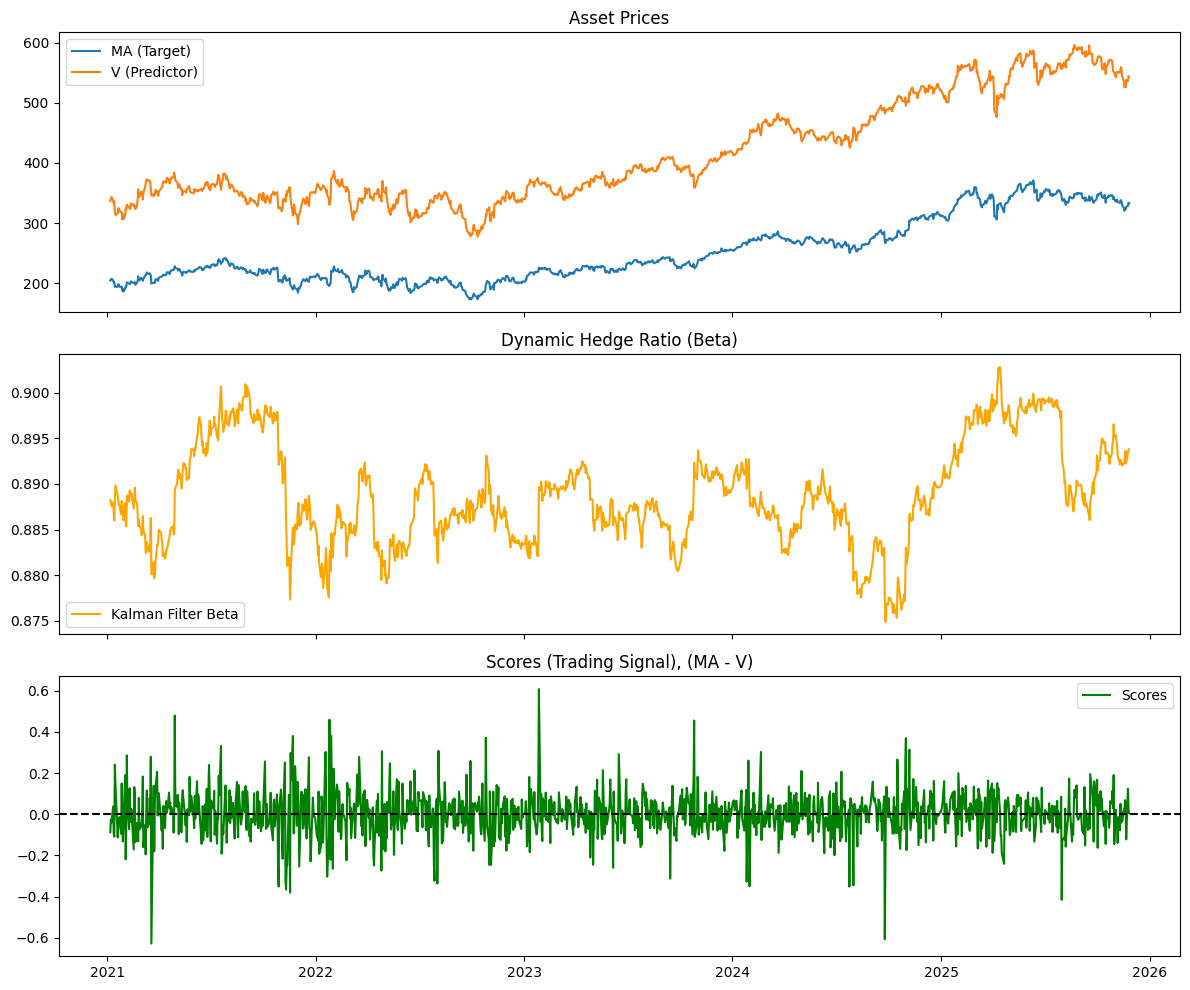

In [28]:
PlotsPriceBased(pair=pair3, start_date=BT_Start, end_date=BT_End)

## Module 4: Strategy Application

We also want to avoid trading for the first few days of the strategy bc the beta needs to update needs to adapt 

The enter and exit signals are completely based on **spread** values. We denote the threhold for a sell position as $\theta_{out}$ and threshold for buy position as $\theta_{in}$. The values use for a buy and sell position is $1$ and $-1$. 

$$ 
P_{i} = \begin{cases}
1 &,\ Z_{i-1} < -\theta_{in} \\ 
1 &,\ Z_{i-1} > \theta_{in} \\
-1 &,\ Z_{i-1} > -\theta_{out} \\ 
-1 &,\ Z_{i-1} < \theta_{out} \\
0 &,\ \text{Otherwise}  
\end{cases}
$$

Conditions for trades:
1. Spread is extremly negative the predictor stock Y is heavily undervalued and stock X is overvalued, **Buy Asset Y** and **Sell Asset X** this is represented as $P_{i} = 1$, then to close position **Buy Asset X** and **Sell Asset Y** as $P_{i} = -1$.
2. Spread is extremly positive the predictor stock X is heavily undervalued and stock Y is overvalued, **Buy Asset X** and **Sell Asset Y** this is represented as $P_{i} = -1$, then to close position **Buy Asset Y** and **Sell Asset X** as $P_{i} = 1$

Need to check the rolling covariance before every trade

#### Trading Signal

In [18]:
def signals(df, theta_in, theta_out):
    """
    Add trading signals (0,-1,1) to dataframe using scores
    """
    column_names = list(df.columns)
    score_index = column_names.index('Scores')

    signals = [0] * len(df)
    
    for t in range(1,len(df)):
        current_score = df.iat[t,score_index]
        prev_signal = signals[t-1]
        # Enter when current scores > enter threshold AND previous score is 0
        if (current_score >= theta_in) and (prev_signal == 0):
            signals[t] = -1
        # Enter when current scores < -enter threshold AND previous score is 0
        elif (current_score <= -theta_in) and (prev_signal == 0):
            signals[t] = 1
        # Close the positive spread position, current score < exit threshold AND signal is -1
        elif (current_score <= theta_out) and (prev_signal == -1):
            signals[t] = 0
        # Close the negative spread position, current score > exit threshold AND signal is 1
        elif (current_score >= -theta_out) and (prev_signal == 1):
            signals[t] = 0
        # Keep current position
        else:
            signals[t] = signals[t-1]

    df['Signals'] = signals
    return df


We keep the $1$ value to indicate that we are still in the long postion and $-1$ to indicate when we are in a short postion. Then once we have a $0$ we exit our position and remains $0$ until we enter another position.

#### Return Values from Strategy

In [19]:
def apply_strategy(df, stop_loss_threshold=3.0):
    """
    Convert raw signals into actual held positions, handling state and risk.
    """
    positions = [0] * len(df) # Initialize list to store state (1, -1, or 0)
    current_pos = 0 
    
    # We iterate because 'holding' a position depends on yesterday's state
    for i in range(1, len(df)):
        z_score = df['Scores'].iloc[i]
        raw_signal = df['Signals'].iloc[i]
        
        # --- STOP LOSS LOGIC ---
        # If the spread blows out too wide, force a close
        if abs(z_score) > stop_loss_threshold:
            current_pos = 0 # Liquidate
            
        # --- ENTRY LOGIC ---
        # Only enter if we are currently flat (0)
        elif current_pos == 0 and raw_signal != 0:
            current_pos = raw_signal 
            
        # --- EXIT LOGIC ---
        # If the raw signal says 'Exit' (z-score near 0), close position
        elif current_pos != 0 and raw_signal == 0: # Note: raw_signal is 0 when z < exit_cutoff
            # Additional check: You might want to ensure it actually crossed 0, 
            # but using the raw_signal from step 1 is the cleanest way.
            current_pos = 0
            
        # --- HOLD LOGIC ---
        # If no entry/exit/stop event, keep doing what we did yesterday
        else:
            positions[i] = current_pos
            continue # Skip the assignment below to keep the flow clear
            
        positions[i] = current_pos

    df['Positions'] = positions
    return df

## Module 5: Backtesting

In [ ]:
def run_backtest_market_neutral(df, initial_capital=100000.0):
    """
    Calculate PnL based on the 'position' column.
    """
    cash = initial_capital
    portfolio_value = []
    
    # Simple loop to update equity based on price moves
    for i in range(len(df)):
        if i == 0:
            portfolio_value.append(initial_capital)
            continue
            
        # Get price changes
        price_change_a = df.iloc[i, 0] - df.iloc[i-1, 0]
        price_change_b = df.iloc[i, 1] - df.iloc[i-1, 1]
        
        # Determine our holdings from the PREVIOUS day's decision
        # (You cannot trade on today's close with today's close price)
        pos = df['Positions'].iloc[i-1]
        hedge = df['Betas'].iloc[i-1]
        
        # Position Logic 1:
        # If Pos = 1 (Long Spread): Long A, Short B
        # If Pos = -1 (Short Spread): Short A, Long B

        # Position Logic 2:
        # If Pos = 1 (Long Spread): Long A
        # If Pos = -1 (Short Spread): Long B
        
        # Calculate simplified PnL per unit (assuming 1 share of A)
        if pos == 1:
            daily_pnl = (100 * price_change_a) + (-100 * hedge * price_change_b)
        elif pos == -1:
            daily_pnl = (-100 * price_change_a) + (100 * hedge * price_change_b)
        else:
            daily_pnl = 0

        # if pos == 1: 
        #     daily_pnl = 100 * price_change_a
        # if pos == -1:
        #     daily_pnl = 100 * price_change_b
        # else:
        #     daily_pnl = 0

        # Add PnL to cash (Mark to Market)
        cash += daily_pnl
        portfolio_value.append(cash)
        
    df['portfolio_value'] = portfolio_value
    return df

#### Plots

In [ ]:
# Opimization of Entry and Exit Thresholds Period
Opt_Start = '2016-01-02'
Opt_End = '2020-12-31' 

# Backtesting Period
BT_Start = '2021-01-02'
BT_End = '2025-11-28'

start_date = BT_Start
end_date = BT_End

In [22]:
# PlotReturnsBased(pair, start_date, end_date)

In [23]:
# PlotsPriceBased(pair, start_date, end_date)

In [24]:
# Vaild Stock Pairs
VALID_PAIRS

[['V', 'MA'], ['GOOGL', 'GOOG'], ['XOM', 'CVX']]

In [25]:
theta_out_ret = 1
theta_in_ret = 3
stop_loss = 4

Calcuting the returns for each pair then adding the returns together respectively

In [ ]:
all_returns_data = pd.DataFrame()

for pair in VALID_PAIRS:
    # Applying Kalman Filter to get Z-Scores and Hedge ratios (log prices)
    data = DataPriceBased(pair, start_date, end_date)

    # Generate Trading Signals
    data = signals(df=data, theta_in=theta_in_ret, theta_out=theta_out_ret)

    # Implement Algorithm 
    data = apply_strategy(df=data, stop_loss_threshold=stop_loss)

    # Evaluate Performance
    data = run_backtest_market_neutral(data)

    # Get returns of strategy
    returns = data['portfolio_value'].pct_change().dropna()

    all_returns_data[pair[0] + '_' + pair[1]] = returns


# Get benchmark returns (buy and hold)
benchmark_buyhold_returns = yf.download(start=start_date, end=end_date, tickers=pair, auto_adjust=True)['Close'].pct_change().dropna()
benchmark_buyhold_returns = benchmark_buyhold_returns.sum(axis=1)

# Get benchmark of S&P 500
benchmark_sp500_returns = yf.download(start=start_date, end=end_date, tickers='^GSPC', auto_adjust=True)['Close'].pct_change().dropna()

# Sum the returns for each row
strategy_rets = all_returns_data.sum(axis=1)


[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  1 of 1 completed


#### Backtest Results

Start date,2021-01-07
End date,2025-11-26
Total months,58
,Backtest
Annual return,0.0%
Cumulative returns,0.0%
Annual volatility,0.0%
Sharpe ratio,NaN
Calmar ratio,NaN
Stability,NaN
Max drawdown,0.0%


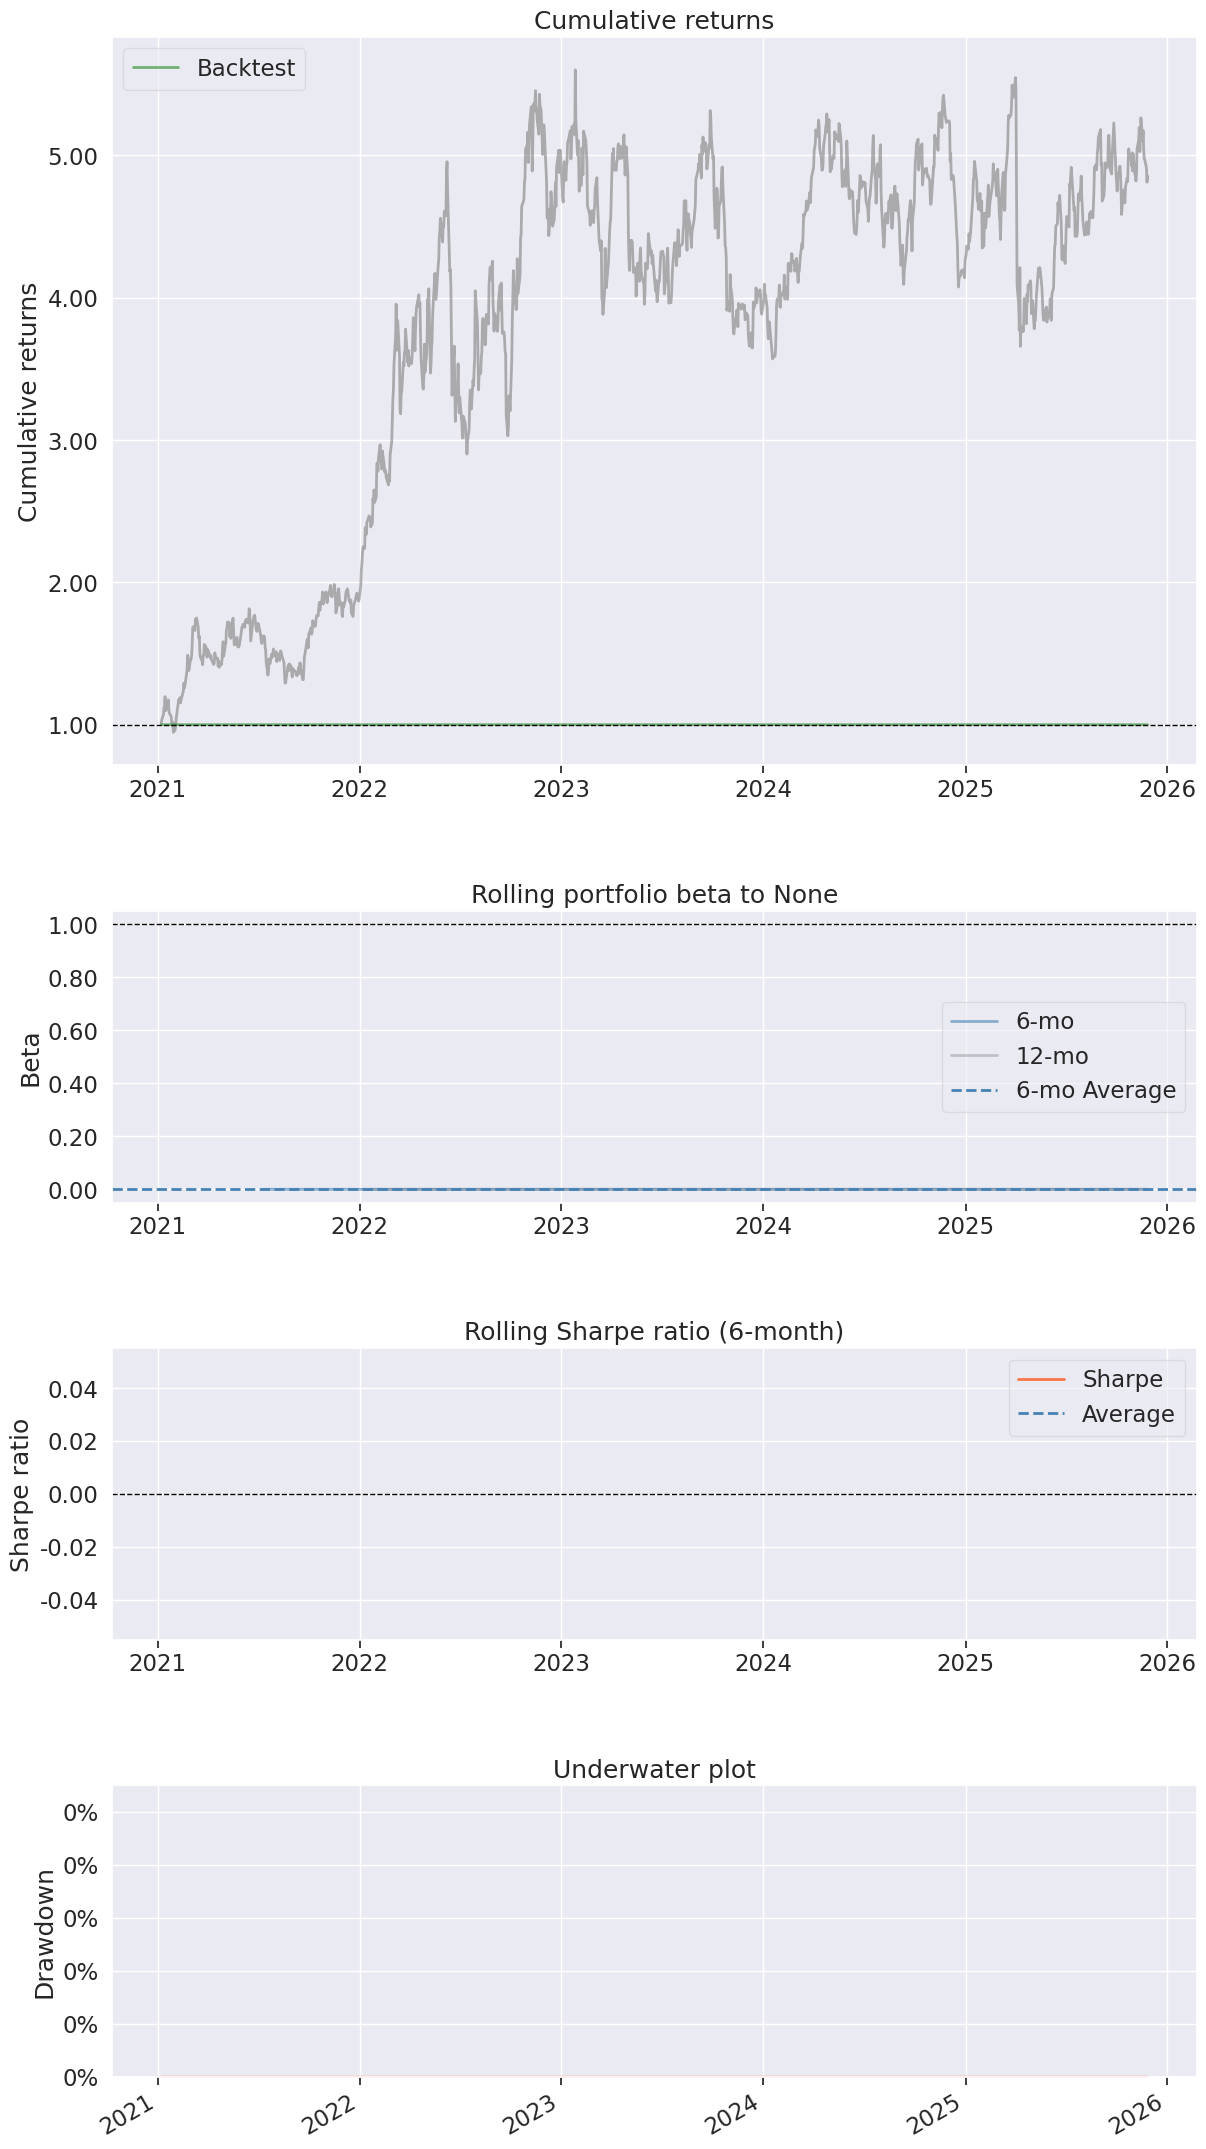

In [27]:
backtest_buyhold = pf.create_simple_tear_sheet(returns=strategy_rets, benchmark_rets=benchmark_buyhold_returns)


#### Current Issues

1. Low returns (Transaction costs would worsen these returns)
2. Not enough signals
3. Not enough stocks pairs to trade with

## Next Steps

1. Selecting more potential pairs 
    - Looking at well estiblished companies in our countries to see if they are correlated with any of well established companies in North America
    - Comparing some small cap stocks to the larger cap stocks in the same industry producing very similar products
2. Optimize the entry and exit thresholds
    - Look into machine learning methods (Baysian Optimization) 
3. Optimize position sizing (kelly cretition)